# C1 · Case-mix-adjusted length of stay in FONASA GRD hospitals, 2023-2024
Business Intelligence IIB423T-1 · GROUP_01 (Matías López, Cristóbal Ramírez) · C1 version 1.0 (29-09-2026)

**Purpose.** Develop candidate B from W1 into a defensible analysis: profile and prepare the FONASA GRD extracts, close the definition of the length-of-stay (LOS) benchmark and its limits (W1 feedback), validate it with sensitivity checks, and explore where case-mix-adjusted excess stay and extreme stays concentrate.

**Run order.** `analysis/01_extraer_grd.py` (already run on the official FONASA files; produced `data/extracted/*.csv.gz`) → this notebook, top to bottom. The report and slides were written from these outputs and edited manually in Word and PowerPoint. All paths are relative to `analysis/`.

**Inputs (unchanged).** `data/extracted/grd_2023_extracto.csv.gz`, `data/extracted/grd_2024_extracto.csv.gz` (uncleaned extracts), `data/reference/Tablas_maestras_bases_GRD.xlsx` (FONASA dictionary), `data/reference/establecimientos_datosgobcl.csv` (MINSAL facilities). **Outputs.** `data/processed/c1_*.csv` and `data/figures/c1_*.png`. Original files are never overwritten.

Column names and category values are kept as published by FONASA (Spanish) so they can be traced to the dictionary. Key terms: `FECHA_INGRESO`/`FECHAALTA` admission/discharge date; `TIPO_ACTIVIDAD` episode type (HOSPITALIZACIÓN inpatient, CMA major ambulatory surgery); `TIPO_INGRESO` admission type (URGENCIA emergency, PROGRAMADA elective, OBSTETRICA obstetric); `TIPOALTA` discharge type (DOMICILIO home, FALLECIDO death, DERIVACIÓN transfer out); `IR_29301_COD_GRD` IR-GRD 3.0 code (6 digits: base GRD in the first 5, severity in the last).

In [1]:
import hashlib, sys, platform, gzip
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter

BASE = Path("..")
EXT, REF = BASE/"data/extracted", BASE/"data/reference"
OUT, FIG = BASE/"data/processed", BASE/"data/figures"
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

BLUE, ORANGE, GREY, INK, INK2, TEAL = "#2a78d6", "#eb6834", "#b8b7b2", "#0b0b0b", "#52514e", "#1a9e8f"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 8.5, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": INK2, "axes.labelcolor": INK,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": "#e6e6e3",
                     "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.titlesize": 9, "axes.titlelocation": "left"})
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| matplotlib", matplotlib.__version__, "|", platform.system())

def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()
inputs = pd.DataFrame([{"file": str(p.relative_to(BASE)), "MB": round(p.stat().st_size/1e6, 1), "sha256": sha256(p)}
                       for p in sorted(EXT.glob("*.gz")) + sorted(REF.glob("*"))])
inputs.to_csv(OUT/"c1_00_input_files.csv", index=False)
inputs

Python 3.12.3 | pandas 3.0.2 | numpy 2.4.4 | matplotlib 3.10.8 | Linux


,file,MB,sha256
0,data/extracted/grd_2023_extracto.csv.gz,40.2,dbe960f33b21837589bda4c989fcada57ff70de8e57271...
1,data/extracted/grd_2024_extracto.csv.gz,43.2,7bb1f18b0a9817a578bc2c786f151c28c25965af20cf14...
2,data/reference/Tablas_maestras_bases_GRD.xlsx,0.1,29da22ac27a79a5f3d62e0b97fcff79dcaf1f19908dcf5...
3,data/reference/establecimientos_datosgobcl.csv,2.5,21c596531528078107b01388716f93d98516f7a9da1817...


## 1. Profiling the source extracts
### 1.1 Structure, types and completeness of every column
The extracts are read as text, exactly as written by `01_extraer_grd.py` (no values were cleaned there). For each column we record the share of empty values, the share of the explicit code `DESCONOCIDO` (unknown), the number of distinct values and an example. The column `timing` is **our classification** of when the field becomes known during the episode (admission vs discharge/coding); it is used later to separate legitimate inputs from leakage in a future ML task and must be confirmed against FONASA documentation.

In [2]:
TIMING = {  # our reading of the FONASA fields; to be confirmed (see report, section 7)
 "COD_HOSPITAL": "admission", "SEXO": "admission", "PROVINCIA": "admission", "COMUNA": "admission",
 "PREVISION": "admission", "SERVICIO_SALUD": "admission", "TIPO_PROCEDENCIA": "admission",
 "TIPO_INGRESO": "admission", "ESPECIALIDAD_MEDICA": "uncertain", "TIPO_ACTIVIDAD": "admission (planned)",
 "FECHA_INGRESO": "admission", "SERVICIOINGRESO": "admission", "FECHAALTA": "discharge (outcome)",
 "SERVICIOALTA": "discharge", "TIPOALTA": "discharge", "DIAGNOSTICO1": "discharge coding",
 "USOSPABELLON": "during stay", "IR_29301_COD_GRD": "discharge coding", "IR_29301_PESO": "discharge coding",
 "IR_29301_SEVERIDAD": "discharge coding", "IR_29301_MORTALIDAD": "discharge coding",
 "HOSPPROCEDENCIA": "admission", "N_DIAG": "discharge coding", "N_PROC": "discharge coding",
 "EDAD_ANIOS": "admission", "ANIO_BASE": "file metadata"}

prof, raw_rows, dup_hashes = [], {}, {}
for y in (2023, 2024):
    d = pd.read_csv(EXT/f"grd_{y}_extracto.csv.gz", dtype=str, keep_default_na=False)
    raw_rows[y] = len(d)
    # exact duplicate rows (all 26 columns identical); hash per row to save memory
    dup_hashes[y] = pd.util.hash_pandas_object(d, index=False)
    for c in d.columns:
        s = d[c]
        prof.append({"year": y, "column": c, "empty_%": round((s == "").mean()*100, 4),
                     "DESCONOCIDO_%": round((s == "DESCONOCIDO").mean()*100, 4),
                     "distinct": s.nunique(), "example": s[s != ""].iloc[0] if (s != "").any() else "",
                     "timing": TIMING.get(c, "")})
    del d
prof = pd.DataFrame(prof)
profile = prof.pivot_table(index=["column", "timing"], columns="year",
                           values=["empty_%", "DESCONOCIDO_%", "distinct"], aggfunc="first")
profile.columns = [f"{a}_{b}" for a, b in profile.columns]
profile = profile.reset_index().merge(prof[prof.year == 2024][["column", "example"]], on="column")
profile.to_csv(OUT/"c1_01_column_profile.csv", index=False)
print("Rows per file:", raw_rows)
profile

Rows per file: {2023: 1039587, 2024: 1085813}


,column,timing,DESCONOCIDO_%_2023,DESCONOCIDO_%_2024,distinct_2023,distinct_2024,empty_%_2023,empty_%_2024,example
0,ANIO_BASE,file metadata,0.0000,0.0000,1,1,0.0000,0.0000,2024
1,COD_HOSPITAL,admission,0.0000,0.0000,68,72,0.0000,0.0000,107102
2,COMUNA,admission,0.0005,0.0006,347,344,0.0000,0.0000,VILLA ALEMANA
3,DIAGNOSTICO1,discharge coding,0.0000,0.0000,7647,7728,0.0000,0.0000,H26.9
4,EDAD_ANIOS,admission,0.0000,0.0000,111,110,0.0010,0.0051,84
5,ESPECIALIDAD_MEDICA,uncertain,0.0000,0.0000,69,73,0.0000,0.0000,OFTALMOLOGÍA
6,FECHAALTA,discharge (outcome),0.0000,0.0000,365,366,0.0000,0.0000,2024-03-23
7,FECHA_INGRESO,admission,0.0000,0.0048,627,630,0.0000,0.0000,2024-03-23
8,HOSPPROCEDENCIA,admission,0.0000,0.0000,391,73,86.5210,91.4721,HOSPITAL SAN PABLO (COQUIMBO)
9,IR_29301_COD_GRD,discharge coding,0.0029,0.0014,985,989,0.0000,0.0000,022360


### 1.2 Candidate keys and duplicate rows
The extract has **no episode identifier** (the encrypted patient identifier was dropped at extraction for data minimisation). We therefore test whether whole rows are repeated. An identical row can be a true duplicate or two genuine episodes that share every retained field (same hospital, dates, GRD, age, sex, etc.), and the extract cannot tell them apart.

In [3]:
dups = pd.DataFrame({y: {"rows": raw_rows[y], "exact_duplicate_rows": int(dup_hashes[y].duplicated().sum()),
                         "exact_duplicate_%": round(dup_hashes[y].duplicated().mean()*100, 3)} for y in (2023, 2024)}).T
dups.to_csv(OUT/"c1_02_duplicates.csv"); del dup_hashes
dups

,rows,exact_duplicate_rows,exact_duplicate_%
2023,1039587.0,1306.0,0.126
2024,1085813.0,1621.0,0.149


### 1.3 Loading the fields used by the analysis and parsing types
Only the columns needed for the length-of-stay line are loaded for the rest of the notebook. Dates are parsed with each year's observed format (W1 finding: 2023 `DD-MM-YYYY`, 2024 `YYYY-MM-DD`); the GRD weight uses a decimal comma.

In [4]:
USE = ["COD_HOSPITAL", "SEXO", "PREVISION", "TIPO_PROCEDENCIA", "TIPO_INGRESO", "ESPECIALIDAD_MEDICA", "TIPO_ACTIVIDAD",
       "FECHA_INGRESO", "SERVICIOINGRESO", "FECHAALTA", "TIPOALTA", "IR_29301_COD_GRD", "IR_29301_PESO",
       "IR_29301_SEVERIDAD", "HOSPPROCEDENCIA", "EDAD_ANIOS", "N_PROC", "ANIO_BASE"]
FMT = {2023: "%d-%m-%Y", 2024: "%Y-%m-%d"}
parts = []
for y in (2023, 2024):
    d = pd.read_csv(EXT/f"grd_{y}_extracto.csv.gz", dtype=str, keep_default_na=False, usecols=USE)
    fmt_ok = {c: d[c].str.match(r"^\d{2}-\d{2}-\d{4}$" if y == 2023 else r"^\d{4}-\d{2}-\d{2}$").mean() for c in ("FECHA_INGRESO", "FECHAALTA")}
    print(y, "share of dates matching the expected format:", {k: round(v, 6) for k, v in fmt_ok.items()})
    d["ADM"] = pd.to_datetime(d.FECHA_INGRESO, format=FMT[y], errors="coerce")
    d["DIS"] = pd.to_datetime(d.FECHAALTA, format=FMT[y], errors="coerce")
    d["YEAR"] = y
    parts.append(d.drop(columns=["FECHA_INGRESO", "FECHAALTA", "ANIO_BASE"]))
g = pd.concat(parts, ignore_index=True); del parts
for c in ["SEXO", "PREVISION", "TIPO_PROCEDENCIA", "TIPO_INGRESO", "ESPECIALIDAD_MEDICA", "TIPO_ACTIVIDAD",
          "SERVICIOINGRESO", "TIPOALTA", "IR_29301_SEVERIDAD", "COD_HOSPITAL", "IR_29301_COD_GRD"]:
    g[c] = g[c].astype("category")
g["LOS"] = (g.DIS - g.ADM).dt.days
g["WEIGHT"] = pd.to_numeric(g.IR_29301_PESO.str.replace(",", ".", regex=False), errors="coerce")
g["AGE"] = pd.to_numeric(g.EDAD_ANIOS, errors="coerce")
g["N_PROC"] = pd.to_numeric(g.N_PROC, errors="coerce")
g["INPATIENT"] = g.TIPO_ACTIVIDAD == "HOSPITALIZACIÓN"
g = g.drop(columns=["IR_29301_PESO", "EDAD_ANIOS"])
print(f"Rows loaded: {len(g):,} | memory {g.memory_usage(deep=True).sum()/1e6:,.0f} MB")

2023 share of dates matching the expected format: {'FECHA_INGRESO': np.float64(1.0), 'FECHAALTA': np.float64(1.0)}


2024 share of dates matching the expected format: {'FECHA_INGRESO': np.float64(0.999952), 'FECHAALTA': np.float64(1.0)}


Rows loaded: 2,125,400 | memory 261 MB


### 1.4 Coverage by year
Files are organised by **discharge year**. Hospitals present in only one year change coverage, not activity, so comparisons between years use the hospitals present in both.

In [5]:
cov = g.groupby("YEAR").agg(episodes=("COD_HOSPITAL", "size"), inpatient=("INPATIENT", "sum"),
                            hospitals=("COD_HOSPITAL", "nunique"), discharge_min=("DIS", "min"),
                            discharge_max=("DIS", "max"), admission_min=("ADM", "min"))
cov["CMA"] = cov.episodes - cov.inpatient
cov["discharges_outside_file_year"] = [int(((g.YEAR == y) & (g.DIS.dt.year != y)).sum()) for y in cov.index]
cov["inpatient_admitted_previous_year_%"] = [round(((g.YEAR == y) & g.INPATIENT & (g.ADM.dt.year < y)).sum() /
                                               ((g.YEAR == y) & g.INPATIENT).sum()*100, 2) for y in cov.index]
cov.to_csv(OUT/"c1_03_coverage.csv"); 
hy = g.groupby(["COD_HOSPITAL", "YEAR"], observed=True).size().unstack()
COMMON = hy.dropna().index.astype(str)
print("Hospitals in both years:", len(COMMON), "| only in one year:", list(hy[hy.isna().any(axis=1)].index.astype(str)))
cov

Hospitals in both years: 68 | only in one year: ['116107', '116111', '119102', '200717']


,episodes,inpatient,hospitals,discharge_min,discharge_max,admission_min,CMA,discharges_outside_file_year,inpatient_admitted_previous_year_%
YEAR,,,,,,,,,
2023,1039587,846043,68,2023-01-01,2023-12-31,2022-01-07,193544,0,1.60
2024,1085813,873772,72,2024-01-01,2024-12-31,2023-01-01,212041,0,1.63


### 1.5 Missing values, recorded zeros and validity checks
A **missing value** is an empty field or an explicit `DESCONOCIDO`. A **recorded zero** is a value that exists and equals zero: a stay admitted and discharged on the same date (LOS = 0) is a real, recorded same-day stay, not a missing duration. `N_PROC = 0` is a derived count: it means no procedure was coded, and the extract cannot separate "no procedure" from "procedure not coded".

In [6]:
dic = pd.read_excel(REF/"Tablas_maestras_bases_GRD.xlsx", sheet_name="IR - GRD", header=None, skiprows=1, dtype=str)
dic.columns = ["CODE", "DESCRIPTION"]; dic["CODE6"] = dic.CODE.str.strip().str.zfill(6)
GRD_DESC = dic.set_index("CODE6").DESCRIPTION.str.strip()
ip = g.INPATIENT
def row(check, n, base, note=""):
    return {"check": check, "n": int(n), "base": int(base), "%": round(n/base*100, 4), "note": note}
val = pd.DataFrame([
  row("Admission date not parseable", g.ADM.isna().sum(), len(g)),
  row("Discharge date not parseable", g.DIS.isna().sum(), len(g)),
  row("Negative LOS (discharge before admission)", (g.LOS < 0).sum(), len(g)),
  row("Inpatient stays with LOS = 0 (recorded same-day stay)", (ip & (g.LOS == 0)).sum(), ip.sum(), "recorded zero, kept"),
  row("Inpatient stays with LOS > 365 days", (ip & (g.LOS > 365)).sum(), ip.sum(), "valid long stays, kept"),
  row("CMA episodes with LOS > 1 day", ((~ip) & (g.LOS > 1)).sum(), (~ip).sum(), "CMA outside scope"),
  row("GRD code not in IR-GRD dictionary (incl. DESCONOCIDO)", (~g.IR_29301_COD_GRD.astype(str).isin(dic.CODE6)).sum(), len(g)),
  row("GRD weight not numeric", g.WEIGHT.isna().sum(), len(g)),
  row("Severity outside {0,1,2,3}", (~g.IR_29301_SEVERIDAD.isin(list("0123"))).sum(), len(g)),
  row("Inpatient stays with severity 0", (ip & (g.IR_29301_SEVERIDAD == "0")).sum(), ip.sum()),
  row("Age missing", g.AGE.isna().sum(), len(g)),
  row("Age < 0 or > 110", ((g.AGE < 0) | (g.AGE > 110)).sum(), len(g)),
  row("SEXO = DESCONOCIDO", (g.SEXO == "DESCONOCIDO").sum(), len(g)),
  row("TIPO_INGRESO = DESCONOCIDO (inpatient)", (ip & (g.TIPO_INGRESO == "DESCONOCIDO")).sum(), ip.sum()),
  row("Last digit of GRD code differs from severity field", (g.IR_29301_COD_GRD.astype(str).str[-1] != g.IR_29301_SEVERIDAD.astype(str)).sum(), len(g), "code structure check"),
  row("N_PROC = 0 (no procedure coded; inpatient)", (ip & (g.N_PROC == 0)).sum(), ip.sum(), "recorded zero of a derived count"),
])
val.to_csv(OUT/"c1_04_validity_checks.csv", index=False)
val

,check,n,base,%,note
0,Admission date not parseable,52,2125400,0.0024,
1,Discharge date not parseable,0,2125400,0.0000,
2,Negative LOS (discharge before admission),0,2125400,0.0000,
3,Inpatient stays with LOS = 0 (recorded same-da...,89180,1719815,5.1854,"recorded zero, kept"
4,Inpatient stays with LOS > 365 days,152,1719815,0.0088,"valid long stays, kept"
5,CMA episodes with LOS > 1 day,419,405585,0.1033,CMA outside scope
6,GRD code not in IR-GRD dictionary (incl. DESCO...,47,2125400,0.0022,
7,GRD weight not numeric,45,2125400,0.0021,
8,"Severity outside {0,1,2,3}",45,2125400,0.0021,
9,Inpatient stays with severity 0,16,1719815,0.0009,


**Reading.** Critical fields for LOS are essentially complete and valid: no negative stays and only a handful of unparseable admission dates and unknown GRD codes. Same-day inpatient stays are recorded values and are retained. The main risks for the analysis are therefore not missing data but definitions (what counts as an extreme stay, which reference is "expected") and coverage.

### 1.6 Consistency between years
The benchmark pools 2023 and 2024, so the category sets and code systems must mean the same in both files.

In [7]:
cons = []
for c in ["TIPO_ACTIVIDAD", "TIPO_INGRESO", "TIPOALTA", "TIPO_PROCEDENCIA", "IR_29301_SEVERIDAD", "SEXO", "PREVISION", "SERVICIOINGRESO", "ESPECIALIDAD_MEDICA"]:
    a = set(g.loc[g.YEAR == 2023, c].astype(str).unique()); b = set(g.loc[g.YEAR == 2024, c].astype(str).unique())
    cons.append({"field": c, "categories_2023": len(a), "categories_2024": len(b), "only_2023": "; ".join(sorted(a - b))[:120], "only_2024": "; ".join(sorted(b - a))[:120]})
a = set(g.loc[(g.YEAR == 2023) & ip, "IR_29301_COD_GRD"].astype(str))
b = set(g.loc[(g.YEAR == 2024) & ip, "IR_29301_COD_GRD"].astype(str))
cons.append({"field": "IR_29301_COD_GRD (inpatient)", "categories_2023": len(a), "categories_2024": len(b), "only_2023": f"{len(a-b)} codes", "only_2024": f"{len(b-a)} codes"})
cons = pd.DataFrame(cons); cons.to_csv(OUT/"c1_05_consistency_categories.csv", index=False)
los_year = g[ip & g.LOS.notna() & g.COD_HOSPITAL.astype(str).isin(COMMON)].groupby("YEAR").LOS.agg(["count", "mean", "median"])
print("LOS in the 68 common hospitals by year:\n", los_year.round(2))
cons

LOS in the 68 common hospitals by year:
        count  mean  median
YEAR                      
2023  846043  7.11     3.0
2024  857326  7.05     3.0


,field,categories_2023,categories_2024,only_2023,only_2024
0,TIPO_ACTIVIDAD,2,2,,
1,TIPO_INGRESO,4,4,,
2,TIPOALTA,10,10,,
3,TIPO_PROCEDENCIA,17,17,,
4,IR_29301_SEVERIDAD,5,5,,
5,SEXO,3,3,,
6,PREVISION,13,13,,
7,SERVICIOINGRESO,88,89,CIRUGÍA TÓRAX,Área de Hospitalización de Cuidados Intensivos...
8,ESPECIALIDAD_MEDICA,69,73,,ADOLESCENCIA (PEDIATRIA); IMAGENOLOGÍA; NUTRIÓ...
9,IR_29301_COD_GRD (inpatient),788,788,4 codes,4 codes


## 2. Join validation: hospital code → reference tables
The only join used is `COD_HOSPITAL` (DEIS facility code) → (a) the `Hospitales` sheet of FONASA's dictionary (conformity of codes) and (b) the MINSAL facilities file (hospital name, complexity level and region). Expected cardinality: many episodes to one facility (m:1). We check key uniqueness on the reference side, matches, unmatched records and the row count before and after.

In [8]:
fac = pd.read_csv(REF/"establecimientos_datosgobcl.csv", sep=";", dtype=str)
fon = pd.read_excel(REF/"Tablas_maestras_bases_GRD.xlsx", sheet_name="Hospitales", header=None, skiprows=1, dtype=str)
fon.columns = ["COD", "NAME"]; fon["COD"] = fon.COD.str.strip()
hosp = pd.DataFrame({"COD_HOSPITAL": g.COD_HOSPITAL.cat.categories.astype(str)})
jv = {"facilities_rows": len(fac), "facilities_key_unique": fac.EstablecimientoCodigo.is_unique,
      "fonasa_dictionary_rows": len(fon), "fonasa_key_unique": fon.COD.is_unique,
      "hospital_codes_in_GRD": len(hosp),
      "matched_in_fonasa_dictionary": int(hosp.COD_HOSPITAL.isin(fon.COD).sum()),
      "matched_in_facilities": int(hosp.COD_HOSPITAL.isin(fac.EstablecimientoCodigo).sum())}
info = fac.set_index("EstablecimientoCodigo")[["EstablecimientoGlosa", "NivelComplejidadEstabGlosa", "RegionGlosa"]]
info.columns = ["HOSPITAL", "COMPLEXITY", "REGION"]
n_before = len(g)
g["HOSP_KEY"] = g.COD_HOSPITAL.astype(str)
g = g.join(info, on="HOSP_KEY", how="left", validate="m:1").drop(columns="HOSP_KEY")
jv.update({"rows_before_join": n_before, "rows_after_join": len(g), "episodes_without_match": int(g.HOSPITAL.isna().sum())})
chk = hosp.merge(fon, left_on="COD_HOSPITAL", right_on="COD", how="left").merge(info, left_on="COD_HOSPITAL", right_index=True, how="left")
jv["complexity_levels"] = chk.COMPLEXITY.value_counts().to_dict()
INSTITUTE = chk.loc[chk.HOSPITAL.str.contains("Instituto", case=False, na=False), "COD_HOSPITAL"].tolist()
jv["national_institutes_(name_contains_Instituto)"] = len(INSTITUTE)
g["INSTITUTE"] = g.COD_HOSPITAL.astype(str).isin(INSTITUTE)
pd.Series(jv, name="value").to_frame().to_csv(OUT/"c1_06_join_validation.csv")
chk[["COD_HOSPITAL", "NAME", "HOSPITAL", "COMPLEXITY", "REGION"]].to_csv(OUT/"c1_06b_hospital_reference.csv", index=False)
print(pd.Series(jv).to_string())
print("Hospital codes absent from the FONASA dictionary sheet:", chk.loc[chk.NAME.isna(), ["COD_HOSPITAL", "HOSPITAL"]].values.tolist())
chk.loc[chk.COD_HOSPITAL.isin(INSTITUTE), ["COD_HOSPITAL", "NAME", "COMPLEXITY"]]

facilities_rows                                                                               5616
facilities_key_unique                                                                         True
fonasa_dictionary_rows                                                                         377
fonasa_key_unique                                                                             True
hospital_codes_in_GRD                                                                           72
matched_in_fonasa_dictionary                                                                    71
matched_in_facilities                                                                           72
rows_before_join                                                                           2125400
rows_after_join                                                                            2125400
episodes_without_match                                                                           0
complexity

,COD_HOSPITAL,NAME,COMPLEXITY
20,110110,Instituto Traumatológico Dr. Teodoro Gebauer,Alta Complejidad
30,112103,Instituto Nacional de Enfermedades Respiratori...,Alta Complejidad
31,112104,Instituto de Neurocirugía Dr. Alfonso Asenjo,Alta Complejidad


**Reading.** The join is m:1 on a unique key, all 72 hospital codes match the MINSAL facilities file and 71 match FONASA's dictionary sheet (the exception, 200717 Complejo Asistencial Padre Las Casas, joined the GRD files in 2024 and is absent from that dictionary version), and the row count does not change and the row count does not change, so the join neither duplicates nor drops episodes. Three hospitals are national institutes (name contains "Instituto"); they are used to test the W1 question on referral institutes. A caveat remains: the MINSAL facilities file is the **current** version, so a complexity label could differ from the one valid in 2023-2024. The facility name and complexity are used only for description and stratification; the benchmark itself needs no join.

## 3. Preparation: from source rows to the analysed population
Filters are applied in this order and their effect is recorded. Nothing is imputed or overwritten; every exclusion is a flag on the loaded data.

In [9]:
steps = [("All episodes in the extracts", pd.Series(True, index=g.index))]
m = g.INPATIENT.copy();                                             steps.append(("Inpatient stays (exclude CMA)", m.copy()))
m &= g.LOS.notna() & (g.LOS >= 0);                                  steps.append(("Valid admission and discharge dates", m.copy()))
m &= g.IR_29301_COD_GRD.astype(str).isin(dic.CODE6) & g.WEIGHT.notna(); steps.append(("GRD code in dictionary and numeric weight", m.copy()))
g["ANALYSED"] = m
flow = pd.DataFrame([{"step": s, "episodes_2023": int((k & (g.YEAR == 2023)).sum()), "episodes_2024": int((k & (g.YEAR == 2024)).sum()),
                      "total": int(k.sum())} for s, k in steps])
flow["removed_at_step"] = (-flow.total.diff()).fillna(0).astype(int)
flow["bed_days"] = [int(g.loc[k & g.LOS.notna(), "LOS"].sum()) if i > 0 else np.nan for i, (s, k) in enumerate(steps)]
A = g[g.ANALYSED].copy(); del g
A["GRD"] = A.IR_29301_COD_GRD.astype(str); A["BASE_GRD"] = A.GRD.str[:5]
A["HOSP"] = A.COD_HOSPITAL.astype(str)
flow

,step,episodes_2023,episodes_2024,total,removed_at_step,bed_days
0,All episodes in the extracts,1039587,1085813,2125400,0,NaN
1,Inpatient stays (exclude CMA),846043,873772,1719815,405585,12171139.0
2,Valid admission and discharge dates,846043,873720,1719763,52,12171139.0
3,GRD code in dictionary and numeric weight,846013,873705,1719718,45,12170340.0


## 4. The length-of-stay benchmark (closing the W1 definition)
W1 feedback asked us to close the definition of the stay benchmark and its limits. The full specification:

| Element | Definition |
|---|---|
| Unit | Inpatient GRD episode (discharge), not patient, not bed-day |
| LOS | `FECHAALTA − FECHA_INGRESO` in whole days (same-day stay = 0) |
| Reference population | All analysed inpatient episodes of all GRD hospitals, discharge years 2023 and 2024 pooled (the GRD network itself) |
| Stratum | IR-GRD 3.0 code (6 digits = base GRD × severity). If a code has < 30 reference episodes, its base GRD (5 digits, all severities) is used; if that also has < 30, the episode is **not benchmarkable** |
| Upper cut-off | Q3 + 1.5·IQR of LOS in the stratum (Tukey rule); outlier = LOS > cut-off |
| Expected LOS | Mean LOS of the inlier episodes of the stratum |
| IEMA (inliers) | Σ observed LOS / Σ expected LOS over a hospital's inlier episodes (indirect standardisation); 1 = network behaviour for its case mix |
| Outlier O/E | Observed outliers / Σ stratum outlier rate over the hospital's episodes |
| Uncertainty | 95% interval for IEMA from the ratio-estimator variance, treating episodes as independent |

This mirrors the structure of the official indicator (IEMA over inliers against a ministerial norm with an upper cut-off per GRD), but **our reference is the observed network, not the MINSAL norm**, which is not published with the public files.

In [10]:
K_IQR, MIN_N = 1.5, 30

def build_benchmark(ref, k=K_IQR, min_n=MIN_N):
    """Per-GRD cut-off, expected LOS (inlier mean) and outlier rate, with base-GRD fallback for small codes."""
    def level(key):
        q = ref.groupby(key).LOS.quantile([.25, .75]).unstack(); q.columns = ["Q1", "Q3"]
        q["N"] = ref.groupby(key).size(); q["CUT"] = q.Q3 + k*(q.Q3 - q.Q1)
        r = ref.join(q.CUT, on=key)
        inl = r[r.LOS <= r.CUT]
        q["EXPECTED"] = inl.groupby(key).LOS.mean(); q["P_OUT"] = (r.LOS > r.CUT).groupby(r[key]).mean()
        q["LOWER_CUT"] = q.Q1 - k*(q.Q3 - q.Q1)
        return q
    code, base = level("GRD"), level("BASE_GRD")
    bm = code.copy(); bm["LEVEL"] = "code"
    small = bm.N < min_n
    fb = base.reindex(bm.index.str[:5]); fb.index = bm.index
    for c in ["CUT", "EXPECTED", "P_OUT", "LOWER_CUT"]:
        bm.loc[small, c] = fb.loc[small, c]
    bm.loc[small, "LEVEL"] = "base GRD fallback"
    bad = small & (fb.N.values < min_n)
    bm.loc[bad, ["CUT", "EXPECTED", "P_OUT"]] = np.nan; bm.loc[bad, "LEVEL"] = "not benchmarkable"
    return bm

def apply_benchmark(df, bm):
    d = df.join(bm[["CUT", "EXPECTED", "P_OUT", "LEVEL"]], on="GRD")
    d["BENCH"] = d.CUT.notna()
    d["OUTLIER"] = d.BENCH & (d.LOS > d.CUT)
    d["INLIER"] = d.BENCH & ~d.OUTLIER
    return d

def hospital_kpis(d, by=("HOSP", "YEAR")):
    by = list(by); b = d[d.BENCH]; i = b[b.INLIER]
    k = b.groupby(by).agg(n=("LOS", "size"), bed_days=("LOS", "sum"), crude_mean_los=("LOS", "mean"),
                          mean_weight=("WEIGHT", "mean"), outliers=("OUTLIER", "sum"), exp_outliers=("P_OUT", "sum"))
    k["outlier_bed_days"] = b[b.OUTLIER].groupby(by).LOS.sum()
    k["days_beyond_cut"] = (b.LOS - b.CUT).where(b.OUTLIER).groupby([b[c] for c in by]).sum()
    ii = i.groupby(by).agg(n_inliers=("LOS", "size"), obs=("LOS", "sum"), exp=("EXPECTED", "sum"))
    k = k.join(ii)
    k["IEMA"] = k.obs/k.exp
    resid2 = (i.LOS - i.join(k.IEMA, on=by).IEMA*i.EXPECTED)**2
    k["se"] = np.sqrt(resid2.groupby([i[c] for c in by]).sum())/k.exp
    k["lo"], k["hi"] = k.IEMA - 1.96*k.se, k.IEMA + 1.96*k.se
    k["class"] = np.select([k.lo > 1, k.hi < 1], ["above network", "below network"], "not distinguishable")
    k["pct_outlier"] = k.outliers/k.n; k["outlier_OE"] = k.outliers/k.exp_outliers
    k["pct_bed_days_outliers"] = k.outlier_bed_days.fillna(0)/k.bed_days
    k["excess_inlier_bed_days"] = k.obs - k.exp
    return k

bm = build_benchmark(A)
A = apply_benchmark(A, bm)
bm.assign(DESCRIPTION=GRD_DESC.reindex(bm.index).values).to_csv(OUT/"c1_07_benchmark_by_grd.csv")
lvl = A.groupby("LEVEL").agg(episodes=("LOS", "size"), grd_codes=("GRD", "nunique"))
lvl["episodes_%"] = (lvl.episodes/len(A)*100).round(3)
print("GRD codes by benchmark level:", bm.LEVEL.value_counts().to_dict())
print(f"Episodes below the lower cut-off Q1-1.5IQR: {(A.LOS < A.join(bm.LOWER_CUT, on='GRD').LOWER_CUT).sum():,} "
      f"| GRD codes whose lower cut-off is <= 0: {(bm.LOWER_CUT <= 0).mean():.1%}")
lvl.to_csv(OUT/"c1_08_benchmark_levels.csv"); lvl

GRD codes by benchmark level: {'code': 757, 'base GRD fallback': 28, 'not benchmarkable': 5}
Episodes below the lower cut-off Q1-1.5IQR: 1,366 | GRD codes whose lower cut-off is <= 0: 97.5%


,episodes,grd_codes,episodes_%
LEVEL,,,
base GRD fallback,403,28,0.023
code,1719299,757,99.976
not benchmarkable,16,5,0.001


### 4.1 Network-level results of the benchmark

In [11]:
net = A[A.BENCH].groupby("YEAR").apply(lambda d: pd.Series({
    "benchmarkable_stays": len(d), "mean_los": d.LOS.mean(), "median_los": d.LOS.median(),
    "p90_los": d.LOS.quantile(.9), "pct_outlier": d.OUTLIER.mean(),
    "pct_bed_days_in_outliers": d.loc[d.OUTLIER, "LOS"].sum()/d.LOS.sum(),
    "mean_los_outliers": d.loc[d.OUTLIER, "LOS"].mean(), "mean_los_inliers": d.loc[d.INLIER, "LOS"].mean(),
    "total_bed_days": d.LOS.sum(), "outlier_bed_days": d.loc[d.OUTLIER, "LOS"].sum(),
    "days_beyond_cut": (d.LOS - d.CUT)[d.OUTLIER].sum(), "IEMA_network": d.loc[d.INLIER, "LOS"].sum()/d.loc[d.INLIER, "EXPECTED"].sum()}),
    include_groups=False)
net.to_csv(OUT/"c1_09_network_summary.csv"); net.T.round(3)

YEAR,2023,2024
benchmarkable_stays,846005.000,873697.000
mean_los,7.104,7.050
median_los,3.000,3.000
p90_los,16.000,16.000
pct_outlier,0.067,0.063
pct_bed_days_in_outliers,0.263,0.254
mean_los_outliers,28.026,28.545
mean_los_inliers,5.613,5.610
total_bed_days,6010385.000,6159557.000
outlier_bed_days,1577869.000,1565670.000


### 4.2 Hospital KPIs, with 95% intervals

In [12]:
H = hospital_kpis(A)
H = H.join(pd.DataFrame(A.groupby("HOSP")[["HOSPITAL", "COMPLEXITY", "REGION", "INSTITUTE"]].first()), on="HOSP")
H.to_csv(OUT/"c1_10_hospital_kpis.csv")
H24 = H.xs(2024, level="YEAR")
print("2024 classification:", H24["class"].value_counts().to_dict())
print("2024 IEMA range:", round(H24.IEMA.min(), 3), "-", round(H24.IEMA.max(), 3), "| median CI half-width:", round((H24.hi - H24.lo).median()/2, 3))
print("Correlation with mean GRD weight across hospitals (2024): crude LOS", round(H24[["crude_mean_los", "mean_weight"]].corr().iloc[0, 1], 3),
      "| IEMA", round(H24[["IEMA", "mean_weight"]].corr().iloc[0, 1], 3))
w = H.IEMA.unstack().dropna(); wo = H.pct_bed_days_outliers.unstack().dropna()
STAB = {"hospitals_both_years": len(w), "r_IEMA_2023_2024": w.corr().iloc[0, 1],
        "spearman_IEMA_2023_2024": w.rank().corr().iloc[0, 1], "r_pct_outlier_bed_days_2023_2024": wo.corr().iloc[0, 1],
        "same_class_both_years": int((H["class"].unstack().dropna().nunique(axis=1) == 1).sum())}
pd.Series(STAB).to_csv(OUT/"c1_11_stability.csv", header=["value"]); print(pd.Series(STAB).round(3).to_string())
H24.sort_values("IEMA").iloc[np.r_[0:5, -5:0]][["HOSPITAL", "COMPLEXITY", "n", "crude_mean_los", "mean_weight", "IEMA", "lo", "hi", "pct_bed_days_outliers", "outlier_OE"]].round(3)

2024 classification: {'below network': 33, 'above network': 25, 'not distinguishable': 14}
2024 IEMA range: 0.707 - 1.18 | median CI half-width: 0.019
Correlation with mean GRD weight across hospitals (2024): crude LOS 0.461 | IEMA -0.082
hospitals_both_years                68.000
r_IEMA_2023_2024                     0.929
spearman_IEMA_2023_2024              0.925
r_pct_outlier_bed_days_2023_2024     0.860
same_class_both_years               58.000


,HOSPITAL,COMPLEXITY,n,crude_mean_los,mean_weight,IEMA,lo,hi,pct_bed_days_outliers,outlier_OE
HOSP,,,,,,,,,,
110110,Instituto Traumatológico Dr. Teodoro Gebauer,Alta Complejidad,3091,4.414,1.301,0.707,0.679,0.736,0.155,0.379
112104,Instituto de Neurocirugía Dr. Alfonso Asenjo,Alta Complejidad,3560,6.706,1.942,0.712,0.682,0.743,0.150,0.235
116107,Hospital de Constitución,Mediana Complejidad,2796,4.731,0.694,0.716,0.690,0.742,0.247,0.472
125100,Hospital Regional de Coyhaique,Alta Complejidad,8936,4.412,0.939,0.744,0.726,0.761,0.129,0.399
114101,Complejo Hospitalario Dr. Sótero del Río (Sant...,Alta Complejidad,39183,5.907,1.210,0.786,0.775,0.797,0.234,0.596
129106,Hospital San José de Victoria,Alta Complejidad,7028,6.637,0.874,1.116,1.091,1.141,0.266,0.895
109100,"Complejo Hospitalario San José (Santiago, Inde...",Alta Complejidad,20550,8.578,1.029,1.139,1.123,1.154,0.343,1.514
103100,Hospital Dr. Leonardo Guzmán (Antofagasta),Alta Complejidad,20026,8.344,1.079,1.143,1.127,1.159,0.301,1.586
106102,Hospital Dr. Eduardo Pereira Ramírez (Valparaíso),Alta Complejidad,4314,10.320,1.350,1.162,1.132,1.192,0.248,1.169


## 5. Sensitivity: does the conclusion survive a changed assumption?
Each variant changes one element of the benchmark. We compare the 2024 hospital IEMA with the main definition (Spearman rank correlation, largest absolute change) and count hospitals whose class (above / not distinguishable / below) changes.

In [13]:
def run_variant(ref_mask=None, eval_mask=None, k=K_IQR, min_n=MIN_N, by_year=False, strata=None):
    base = A.drop(columns=["CUT", "EXPECTED", "P_OUT", "LEVEL", "BENCH", "OUTLIER", "INLIER"])
    if eval_mask is not None: base = base[eval_mask.loc[base.index]]
    groups = [None] if strata is None else list(base[strata].dropna().unique())
    out = []
    for s in groups:
        sub = base if s is None else base[base[strata] == s]
        if by_year:
            for y in (2023, 2024):
                ref = sub[sub.YEAR == y]; ref = ref if ref_mask is None else ref[ref_mask.loc[ref.index]]
                out.append(apply_benchmark(sub[sub.YEAR == y], build_benchmark(ref, k, min_n)))
        else:
            ref = sub if ref_mask is None else sub[ref_mask.loc[sub.index]]
            out.append(apply_benchmark(sub, build_benchmark(ref, k, min_n)))
    return hospital_kpis(pd.concat(out))

transfer_or_death = A.TIPOALTA.astype(str).str.startswith("DERIVACI") | (A.TIPOALTA == "FALLECIDO")
VARIANTS = {
 "V1 Cut-off Q3 + 3.0·IQR (only far-out stays are outliers)": dict(k=3.0),
 "V2 Year-specific benchmark (2023 and 2024 separately)": dict(by_year=True),
 "V3 Exclude deaths and transfers out (reference and evaluation)": dict(eval_mask=~transfer_or_death),
 "V4 Peer-group benchmark by hospital complexity level": dict(strata="COMPLEXITY"),
 "V5 Exclude national institutes from the reference population": dict(ref_mask=~A.INSTITUTE),
 "V6 Minimum stratum size 100 instead of 30": dict(min_n=100),
}
sens, VAR = [], {}
for name, kw in VARIANTS.items():
    v = run_variant(**kw).xs(2024, level="YEAR"); VAR[name] = v
    j = H24[["IEMA", "class"]].join(v[["IEMA", "class"]], rsuffix="_v", how="inner")
    sens.append({"variant": name, "hospitals": len(j), "spearman_vs_main": j.IEMA.rank().corr(j.IEMA_v.rank()),
                 "max_abs_change": (j.IEMA - j.IEMA_v).abs().max(), "class_changes": int((j["class"] != j.class_v).sum()),
                 "above_network": int((j.class_v == "above network").sum()), "below_network": int((j.class_v == "below network").sum()),
                 "network_pct_outlier": v.outliers.sum()/v.n.sum(),
                 "max_abs_main_IEMA_minus_1_among_changed": (j.loc[j["class"] != j.class_v, "IEMA"] - 1).abs().max() if (j["class"] != j.class_v).any() else 0.0})
sens = pd.DataFrame(sens)
sens.loc[-1] = {"variant": "V0 Main definition", "hospitals": len(H24), "spearman_vs_main": 1.0, "max_abs_change": 0.0, "class_changes": 0,
                "above_network": int((H24["class"] == "above network").sum()), "below_network": int((H24["class"] == "below network").sum()),
                "network_pct_outlier": H24.outliers.sum()/H24.n.sum(), "max_abs_main_IEMA_minus_1_among_changed": 0.0}
sens = sens.sort_index().reset_index(drop=True)
sens.to_csv(OUT/"c1_12_sensitivity.csv", index=False)
sens.round(3)

,variant,hospitals,spearman_vs_main,max_abs_change,class_changes,above_network,below_network,network_pct_outlier,max_abs_main_IEMA_minus_1_among_changed
0,V0 Main definition,72,1.000,0.000,0,25,33,0.063,0.000
1,V1 Cut-off Q3 + 3.0·IQR (only far-out stays ar...,72,0.986,0.046,7,23,39,0.025,0.023
2,V2 Year-specific benchmark (2023 and 2024 sepa...,72,0.999,0.022,6,28,30,0.065,0.042
3,V3 Exclude deaths and transfers out (reference...,72,0.978,0.071,5,26,33,0.062,0.086
4,V4 Peer-group benchmark by hospital complexity...,72,0.979,0.077,4,27,31,0.063,0.063
5,V5 Exclude national institutes from the refere...,72,1.000,0.060,0,25,33,0.062,0.000
6,V6 Minimum stratum size 100 instead of 30,72,1.000,0.005,0,25,33,0.063,0.000


**Reading.** The hospital ranking is robust to every variant (Spearman rank correlation with the main definition of about 0.98 or higher). Between 0 and 7 of the 72 hospitals change class, and the last column shows that all of them have a main IEMA within 0.09 of 1 (most within 0.05). Changing the cut-off to 3·IQR changes the *level* of the outlier KPI a lot (far fewer outliers) but hardly the ordering of hospitals. Excluding the national institutes from the reference changes nothing material, which answers the W1 concern that they distort the benchmark. Conclusions are therefore stated for hospitals clearly away from 1, and classes near the boundary are read as "not distinguishable", not as a ranking.

## 6. Exploratory analysis
### 6.1 Distribution of length of stay

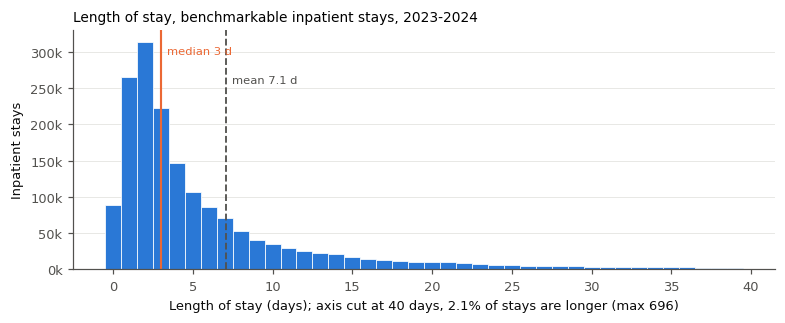

In [14]:
B = A[A.BENCH]
fig, ax = plt.subplots(figsize=(7.2, 3.0))
v = B.loc[B.LOS <= 40, "LOS"]
ax.hist(v, bins=np.arange(-0.5, 40.5, 1), color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvline(B.LOS.median(), color=ORANGE, lw=1.4); ax.axvline(B.LOS.mean(), color=INK2, lw=1.2, ls="--")
ax.text(B.LOS.median()+0.4, ax.get_ylim()[1]*0.9, f"median {B.LOS.median():.0f} d", color=ORANGE, fontsize=7.5)
ax.text(B.LOS.mean()+0.4, ax.get_ylim()[1]*0.78, f"mean {B.LOS.mean():.1f} d", color=INK2, fontsize=7.5)
ax.set_xlabel(f"Length of stay (days); axis cut at 40 days, {(B.LOS > 40).mean():.1%} of stays are longer (max {B.LOS.max():.0f})")
ax.set_ylabel("Inpatient stays"); ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
ax.set_title("Length of stay, benchmarkable inpatient stays, 2023-2024"); ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG/"c1_fig1_los_distribution.png"); plt.show()

### 6.2 Who has extreme stays? Outlier rate and bed-day share by episode characteristics

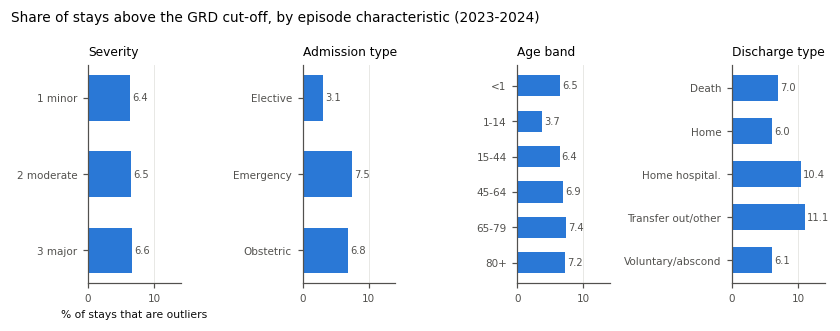

stays  mean_los  median_los  pct_outlier  share_of_stays  share_of_outlier_bed_days  outlier_OE
factor         level                                                                                                                   
Severity       1 minor                 775946     3.875         2.0        0.064           0.451                      0.234       1.000
               2 moderate              521949     6.738         4.0        0.065           0.304                      0.291       1.000
               3 major                 421807    13.386         7.0        0.066           0.245                      0.475       1.002
Admission type Elective                361702     4.225         2.0        0.031           0.210                      0.101       0.452
               Emergency              1058473     9.146         5.0        0.075           0.615                      0.824       1.192
               Obstetric               299429     3.208         2.0        0.068           0.174                      0.075       1.038
Age band       <1                       96726     9.976         4.0        0.065           0.056                      0.078       1.024
               1-14                    182079     4.782         3.0        0.037           0.106                      0.057       0.576
               15-44                   612941     5.034         3.0        0.064           0.356                      0.240       0.975
               45-64                   365382     8.254         4.0        0.069           0.212                      0.261       1.069
               65-79                   324057     9.222         5.0        0.074           0.188                      0.262       1.155
               80+                     138510     8.985         6.0        0.072           0.081                      0.101       1.114
Discharge type Death                    51767    13.691         6.0        0.070           0.030                      0.070       1.083
               Home                   1499825     6.315         3.0        0.060           0.872                      0.691       0.935
               Home hospitalisation     65535    13.167         7.0        0.104           0.038                      0.090       1.619
               Transfer out / other     75172    12.905         5.0        0.111           0.044                      0.135       1.767
               Voluntary / absconded    27403     5.733         3.0        0.061           0.016                      0.013       0.926

In [15]:
def ageband(a):
    return pd.cut(a, [-1, 0, 14, 44, 64, 79, 200], labels=["<1", "1-14", "15-44", "45-64", "65-79", "80+"])
DIS_GROUP = {"DOMICILIO": "Home", "HOSPITALIZACIÓN DOMICILIARIA": "Home hospitalisation", "FALLECIDO": "Death",
             "ALTA VOLUNTARIA": "Voluntary / absconded", "FUGA DEL PACIENTE": "Voluntary / absconded"}
B = B.assign(AGE_BAND=ageband(B.AGE), DISCHARGE=B.TIPOALTA.astype(str).map(DIS_GROUP).fillna("Transfer out / other"),
             ADMISSION=B.TIPO_INGRESO.astype(str).map({"URGENCIA": "Emergency", "PROGRAMADA": "Elective", "OBSTETRICA": "Obstetric"}).fillna("Unknown"),
             SEVERITY=B.IR_29301_SEVERIDAD.astype(str).map({"1": "1 minor", "2": "2 moderate", "3": "3 major"}).fillna("other"))
tot_out_bd = B.loc[B.OUTLIER, "LOS"].sum()
def by_factor(col):
    t = B.groupby(col, observed=True).agg(stays=("LOS", "size"), mean_los=("LOS", "mean"), median_los=("LOS", "median"), pct_outlier=("OUTLIER", "mean"), exp_out=("P_OUT", "mean"))
    t["share_of_stays"] = t.stays/len(B); t["share_of_outlier_bed_days"] = B[B.OUTLIER].groupby(col, observed=True).LOS.sum()/tot_out_bd
    t["outlier_OE"] = t.pct_outlier/t.exp_out
    return t.drop(columns="exp_out")
FACT = {"Severity": "SEVERITY", "Admission type": "ADMISSION", "Age band": "AGE_BAND", "Discharge type": "DISCHARGE"}
fact = pd.concat({k: by_factor(v) for k, v in FACT.items()}); fact.index.names = ["factor", "level"]
fact = fact[fact.stays >= 1000]
fact.to_csv(OUT/"c1_13_outliers_by_factor.csv"); 
fig, axes = plt.subplots(1, 4, figsize=(7.6, 3.0), sharex=True)
for ax, (k, _) in zip(axes, FACT.items()):
    t = fact.loc[k]
    ax.barh(t.index.astype(str).str.replace("Voluntary / absconded", "Voluntary/abscond").str.replace("Transfer out / other", "Transfer out/other").str.replace("Home hospitalisation", "Home hospital."),
            t.pct_outlier*100, color=BLUE, height=0.6)
    for yi, vv in enumerate(t.pct_outlier*100): ax.text(vv+0.3, yi, f"{vv:.1f}", va="center", fontsize=6.5, color=INK2)
    ax.set_title(k, fontsize=8); ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.tick_params(labelsize=6.8)
    ax.set_xlim(0, 14)
axes[0].set_xlabel("% of stays that are outliers", fontsize=7)
fig.suptitle("Share of stays above the GRD cut-off, by episode characteristic (2023-2024)", x=0.01, ha="left", fontsize=9)
fig.tight_layout(); fig.savefig(FIG/"c1_fig2_outliers_by_factor.png"); plt.show()
fact.round(3)

**Reading.** Because the cut-off is defined within each GRD, the overall outlier rate is about 6-7% by construction, and differences between groups show *which* episodes exceed the stay typical of their own GRD. The column `outlier_OE` compares each group with the rate expected from its GRD mix. Extreme stays are more frequent among older patients, emergency admissions and stays ending in a transfer or in home hospitalisation; deaths are a special case because death can shorten or lengthen a stay. These are associations in discharge records, not causes.

### 6.3 Where do extreme-stay bed-days concentrate? (GRD level)

{'grd_codes_with_outliers': 764, 'codes_for_50pct': 70, 'codes_for_80pct': 231}


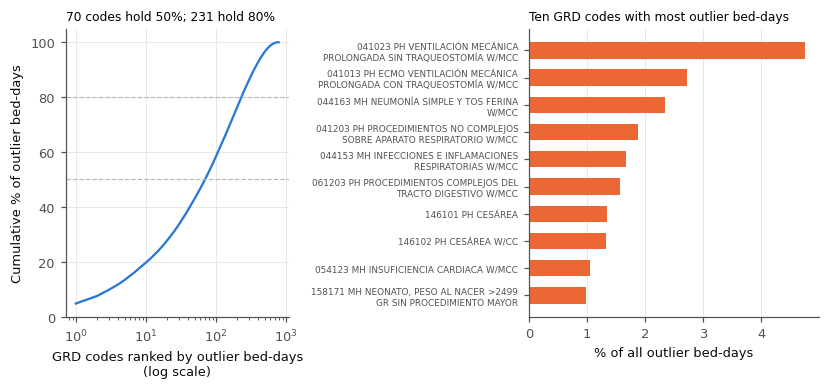

,DESCRIPTION,stays,outliers,outlier_bed_days,cum_share_outlier_bed_days
GRD,,,,,
041023,PH VENTILACIÓN MECÁNICA PROLONGADA SIN TRAQUEO...,19943,1379,149641.0,0.047603
041013,PH ECMO VENTILACIÓN MECÁNICA PROLONGADA CON TR...,6080,384,85785.0,0.074892
044163,MH NEUMONÍA SIMPLE Y TOS FERINA W/MCC,41867,3169,73666.0,0.098326
041203,PH PROCEDIMIENTOS NO COMPLEJOS SOBRE APARATO R...,15840,1143,58974.0,0.117087
044153,MH INFECCIONES E INFLAMACIONES RESPIRATORIAS W...,12707,986,52370.0,0.133746
061203,PH PROCEDIMIENTOS COMPLEJOS DEL TRACTO DIGESTI...,8498,584,49265.0,0.149418
146101,PH CESÁREA,55006,5331,42343.0,0.162888
146102,PH CESÁREA W/CC,29429,2605,41730.0,0.176163
054123,MH INSUFICIENCIA CARDIACA W/MCC,13968,989,33264.0,0.186744


In [16]:
gr = B.groupby("GRD").agg(stays=("LOS", "size"), outliers=("OUTLIER", "sum"), bed_days=("LOS", "sum"))
gr["outlier_bed_days"] = B[B.OUTLIER].groupby("GRD").LOS.sum(); gr = gr.fillna(0)
gr["days_beyond_cut"] = (B.LOS - B.CUT)[B.OUTLIER].groupby(B.GRD[B.OUTLIER]).sum(); gr = gr.fillna(0)
gr = gr.sort_values("outlier_bed_days", ascending=False)
gr["cum_share_outlier_bed_days"] = gr.outlier_bed_days.cumsum()/gr.outlier_bed_days.sum()
gr["DESCRIPTION"] = GRD_DESC.reindex(gr.index).values
gr.to_csv(OUT/"c1_14_grd_concentration.csv")
PARETO = {"grd_codes_with_outliers": int((gr.outliers > 0).sum()),
          "codes_for_50pct": int((gr.cum_share_outlier_bed_days < 0.5).sum()+1),
          "codes_for_80pct": int((gr.cum_share_outlier_bed_days < 0.8).sum()+1)}
print(PARETO)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.6, 3.6), gridspec_kw={"width_ratios": [1, 1.3]})
a1.plot(np.arange(1, len(gr)+1), gr.cum_share_outlier_bed_days*100, color=BLUE)
for p in (50, 80): a1.axhline(p, color=GREY, lw=0.8, ls="--")
a1.set_xscale("log"); a1.set_xlabel("GRD codes ranked by outlier bed-days\n(log scale)"); a1.set_ylabel("Cumulative % of outlier bed-days")
a1.set_title(f"{PARETO['codes_for_50pct']} codes hold 50%; {PARETO['codes_for_80pct']} hold 80%", fontsize=8)
top = gr.head(10)
import textwrap
lab = ["\n".join(textwrap.wrap(f"{c} {str(dsc).strip()}", 40)[:2]) for c, dsc in zip(top.index, top.DESCRIPTION)]
a2.barh(lab[::-1], (top.outlier_bed_days/gr.outlier_bed_days.sum()*100)[::-1], color=ORANGE, height=0.6)
a2.set_xlabel("% of all outlier bed-days"); a2.tick_params(axis="y", labelsize=5.8); a2.grid(axis="y", visible=False)
a2.set_title("Ten GRD codes with most outlier bed-days", fontsize=8)
fig.tight_layout(); fig.savefig(FIG/"c1_fig3_grd_concentration.png"); plt.show()
gr.head(10)[["DESCRIPTION", "stays", "outliers", "outlier_bed_days", "cum_share_outlier_bed_days"]]

### 6.4 Hospitals: adjusted stay with intervals, and its relation to extreme stays

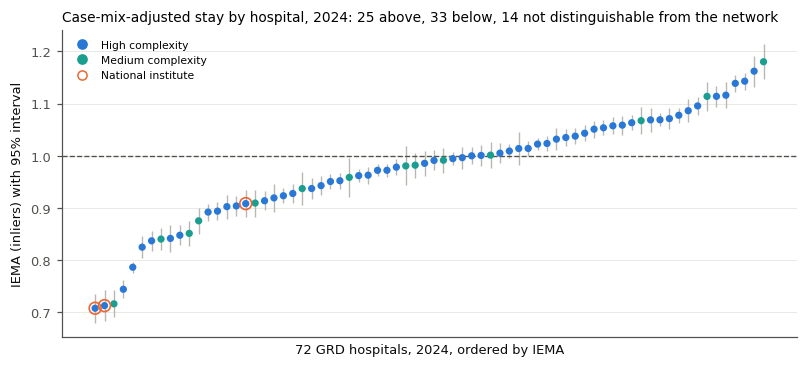

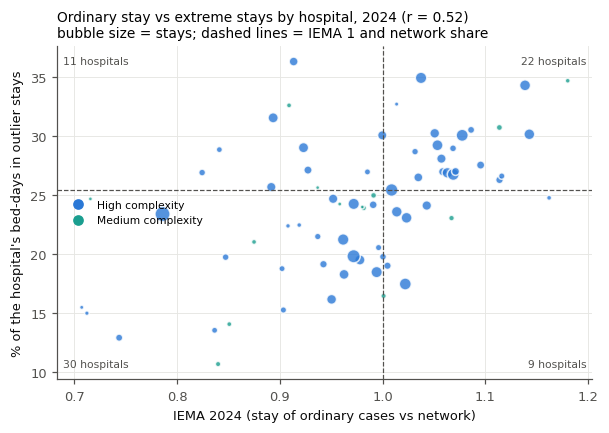

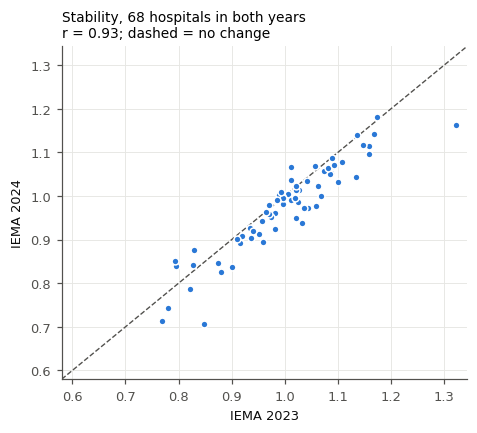

Corr IEMA vs % outlier bed-days (2024): 0.521


In [17]:
h = H24.sort_values("IEMA").reset_index()
col = h.COMPLEXITY.map(lambda c: BLUE if isinstance(c, str) and c.startswith("Alta") else TEAL)
fig, ax = plt.subplots(figsize=(7.4, 3.4))
ax.errorbar(np.arange(len(h)), h.IEMA, yerr=[h.IEMA-h.lo, h.hi-h.IEMA], fmt="none", ecolor=GREY, elinewidth=0.9)
ax.scatter(np.arange(len(h)), h.IEMA, c=col, s=14, zorder=3)
ax.scatter(np.where(h.INSTITUTE)[0], h.IEMA[h.INSTITUTE], facecolors="none", edgecolors=ORANGE, s=60, lw=1.1, zorder=4)
ax.axhline(1, color=INK2, lw=0.9, ls="--"); ax.set_xticks([]); ax.set_xlabel("72 GRD hospitals, 2024, ordered by IEMA")
ax.set_ylabel("IEMA (inliers) with 95% interval")
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=BLUE, label="High complexity"), Line2D([], [], marker="o", ls="", color=TEAL, label="Medium complexity"),
                   Line2D([], [], marker="o", ls="", mfc="none", mec=ORANGE, label="National institute")], frameon=False, fontsize=7, loc="upper left")
ax.set_title(f"Case-mix-adjusted stay by hospital, 2024: {int((h['class']=='above network').sum())} above, {int((h['class']=='below network').sum())} below, {int((h['class']=='not distinguishable').sum())} not distinguishable from the network")
fig.tight_layout(); fig.savefig(FIG/"c1_fig4_iema_2024_intervals.png"); plt.show()

fig, ax = plt.subplots(figsize=(5.6, 4.0))
ax.scatter(H24.IEMA, H24.pct_bed_days_outliers*100, s=H24.n/400, c=[BLUE if str(c).startswith("Alta") else TEAL for c in H24.COMPLEXITY], alpha=0.8, edgecolor="white")
ax.axvline(1, color=INK2, lw=0.8, ls="--"); ax.axhline(net.loc[2024, "pct_bed_days_in_outliers"]*100, color=INK2, lw=0.8, ls="--")
ax.set_xlabel("IEMA 2024 (stay of ordinary cases vs network)"); ax.set_ylabel("% of the hospital's bed-days in outlier stays")
rq = H24[["IEMA", "pct_bed_days_outliers"]].corr().iloc[0, 1]
ax.set_title(f"Ordinary stay vs extreme stays by hospital, 2024 (r = {rq:.2f})\nbubble size = stays; dashed lines = IEMA 1 and network share")
ref_y = net.loc[2024, "pct_bed_days_in_outliers"]
quad = {(True, True): (0.99, 0.97, "right", "top"), (False, True): (0.01, 0.97, "left", "top"), (True, False): (0.99, 0.03, "right", "bottom"), (False, False): (0.01, 0.03, "left", "bottom")}
for (hx, hy_), (xx, yy, ha, va) in quad.items():
    nq = int(((H24.IEMA > 1) == hx).mul((H24.pct_bed_days_outliers > ref_y) == hy_).sum())
    ax.text(xx, yy, f"{nq} hospitals", transform=ax.transAxes, ha=ha, va=va, fontsize=7, color=INK2)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=BLUE, label="High complexity"), Line2D([], [], marker="o", ls="", color=TEAL, label="Medium complexity")], frameon=False, fontsize=7, loc="center left")
fig.tight_layout(); fig.savefig(FIG/"c1_fig5_iema_vs_outlier_share.png"); plt.show()

fig, ax = plt.subplots(figsize=(4.4, 4.0))
ax.scatter(w[2023], w[2024], s=20, color=BLUE, edgecolor="white", zorder=3)
lim = [min(w.min().min(), 0.6)-0.02, max(w.max().max(), 1.3)+0.02]; ax.plot(lim, lim, color=INK2, lw=0.9, ls="--")
ax.set_xlim(lim); ax.set_ylim(lim); ax.set_xlabel("IEMA 2023"); ax.set_ylabel("IEMA 2024")
ax.set_title(f"Stability, {len(w)} hospitals in both years\nr = {STAB['r_IEMA_2023_2024']:.2f}; dashed = no change")
fig.tight_layout(); fig.savefig(FIG/"c1_fig6_iema_stability.png"); plt.show()
print("Corr IEMA vs % outlier bed-days (2024):", round(rq, 3))

**Reading.** In 2024, 25 hospitals have an IEMA interval entirely above 1, 33 entirely below and 14 overlap 1. The spread (about 0.71 to 1.18) is wide relative to the intervals, and the ranking is stable between years (r ≈ 0.93). The three national institutes sit **below** the network, not above as we hypothesised in W1. IEMA is almost uncorrelated with a hospital's mean GRD weight while crude LOS is not, so the adjustment removes the case-mix gradient it is meant to remove. The share of bed-days in extreme stays is related to IEMA but is a distinct signal (r ≈ 0.5): some hospitals have ordinary stays close to the network but many bed-days in extreme stays, which points to different reviews (discharge processes for ordinary cases vs case review of prolonged stays).

Intervals assume independent episodes; clustering within services and patients would widen them, so classes near 1 are fragile.

### 6.5 Monthly pattern (hospitals present in both years)
Before comparing months we check reporting completeness (stays per month). The series is by **discharge month**; the files contain no stays still open at the end of 2024.

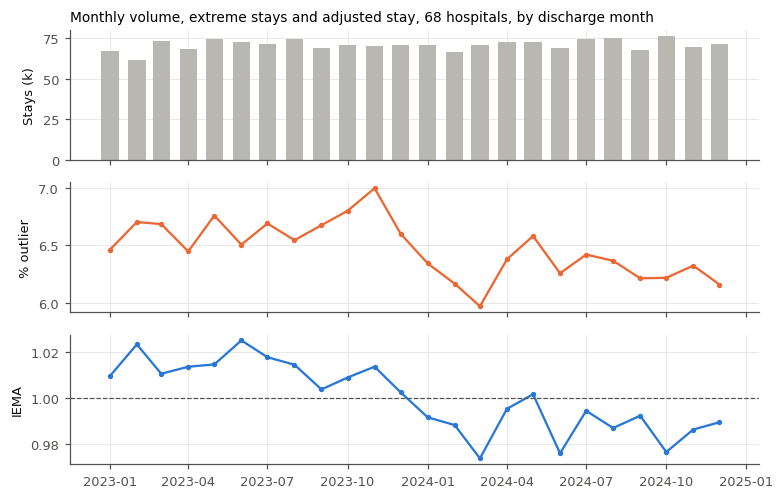

CV of monthly stays: 0.046


,stays,mean_los,pct_outlier,IEMA
MONTH,,,,
2023-01,67289,6.949,0.065,1.009
2023-02,61762,7.107,0.067,1.023
2023-03,73510,7.025,0.067,1.010
2023-04,68411,6.932,0.064,1.014
2023-05,74475,7.126,0.068,1.015
2023-06,73078,7.238,0.065,1.025
2023-07,71597,7.222,0.067,1.018
2023-08,74469,7.103,0.065,1.014
2023-09,69059,7.003,0.067,1.004


In [18]:
M = B[B.HOSP.isin(COMMON)].copy(); M["MONTH"] = M.DIS.dt.to_period("M")
mon = M.groupby("MONTH").agg(stays=("LOS", "size"), mean_los=("LOS", "mean"), pct_outlier=("OUTLIER", "mean"))
mi = M[M.INLIER].groupby("MONTH").agg(o=("LOS", "sum"), e=("EXPECTED", "sum")); mon["IEMA"] = mi.o/mi.e
mon.to_csv(OUT/"c1_15_monthly.csv")
fig, axs = plt.subplots(3, 1, figsize=(7.2, 4.6), sharex=True)
x = mon.index.to_timestamp()
axs[0].bar(x, mon.stays/1000, width=20, color=GREY); axs[0].set_ylabel("Stays (k)")
axs[1].plot(x, mon.pct_outlier*100, color=ORANGE, marker="o", ms=2.5); axs[1].set_ylabel("% outlier")
axs[2].plot(x, mon.IEMA, color=BLUE, marker="o", ms=2.5); axs[2].axhline(1, color=INK2, lw=0.8, ls="--"); axs[2].set_ylabel("IEMA")
axs[0].set_title("Monthly volume, extreme stays and adjusted stay, 68 hospitals, by discharge month")
fig.tight_layout(); fig.savefig(FIG/"c1_fig7_monthly.png"); plt.show()
print("CV of monthly stays:", round(mon.stays.std()/mon.stays.mean(), 3)); mon.round(3)

**Reading.** Monthly volume is stable (coefficient of variation ≈ 5%) and does not drop at the end of 2024, so reporting completeness supports a month-by-month comparison. There is no marked winter peak in adjusted stay. Both the outlier share and the network IEMA are about 2-3% lower throughout 2024 than in 2023 (the axes are zoomed; with a pooled 2023-2024 reference the two years sit either side of 1 by construction). Alternative explanations cannot be separated with these files: a real change in stay management, coding changes within GRDs, or the different extraction lag (the 2023 file was extracted about eight months after year end, the 2024 file about four and a half), which could leave some late-coded, possibly longer, episodes out of the 2024 snapshot.

### 6.6 Size of the signal in bed-days (descriptive, not a saving)

In [19]:
above = H24["class"] == "above network"
SIZE = {"bed_days_2024": H24.bed_days.sum(), "outlier_bed_days_2024": H24.outlier_bed_days.sum(),
        "days_beyond_cut_2024": H24.days_beyond_cut.sum(),
        "excess_inlier_bed_days_hospitals_above": H24.loc[above, "excess_inlier_bed_days"].sum(),
        "hospitals_above": int(above.sum())}
SIZE["beds_equiv_days_beyond_cut"] = SIZE["days_beyond_cut_2024"]/366
SIZE["beds_equiv_excess_inlier_above"] = SIZE["excess_inlier_bed_days_hospitals_above"]/366
pd.Series(SIZE).to_csv(OUT/"c1_16_signal_size.csv", header=["value"]); pd.Series(SIZE).round(1)

bed_days_2024                             6159557.0
outlier_bed_days_2024                     1565670.0
days_beyond_cut_2024                       649246.5
excess_inlier_bed_days_hospitals_above     133177.4
hospitals_above                                25.0
beds_equiv_days_beyond_cut                   1773.9
beds_equiv_excess_inlier_above                363.9
dtype: float64

**Reading.** Two quantities are reported and kept separate: bed-days beyond the GRD cut-off (a property of extreme stays) and inlier bed-days above the network expectation in hospitals whose interval lies above 1. Dividing by 366 converts them into average occupied beds. They describe the size of the gap against the network; they are **not** avoidable days or savings, because the data do not show why the stays were longer.

## 7. Feasibility check for a future ML task (no model is trained)
Candidate task: at admission, flag stays at risk of becoming extreme (outlier). The label uses the GRD cut-off, which is only known at discharge; that is acceptable for a **label**, but not for **inputs**. Below we check (a) label prevalence and stability and (b) whether admission-time fields show any univariate variation in the outlier rate. This does not demonstrate predictive value.

In [20]:
ADM_FIELDS = {"Admission type": "ADMISSION", "Origin (TIPO_PROCEDENCIA)": "TIPO_PROCEDENCIA", "Age band": "AGE_BAND",
              "Admitting unit (SERVICIOINGRESO)": "SERVICIOINGRESO", "Insurance (PREVISION)": "PREVISION", "Sex": "SEXO"}
ml = []
for k, c in ADM_FIELDS.items():
    t = B.groupby(c, observed=True).OUTLIER.agg(["size", "mean"]); t = t[t["size"] >= 1000]
    ml.append({"admission-time field": k, "categories_with_1000+_stays": len(t), "min_outlier_%": t["mean"].min()*100,
               "max_outlier_%": t["mean"].max()*100, "missing_or_unknown_%": (B[c].astype(str).isin(["", "DESCONOCIDO", "nan"])).mean()*100})
ml = pd.DataFrame(ml)
lab = B.groupby("YEAR").OUTLIER.mean()
print("Label prevalence by year:", lab.round(4).to_dict(), "| stays:", B.groupby("YEAR").size().to_dict())
ml.to_csv(OUT/"c1_17_ml_feasibility.csv", index=False); ml.round(2)

Label prevalence by year: {2023: 0.0665, 2024: 0.0628} | stays: {2023: 846005, 2024: 873697}


,admission-time field,categories_with_1000+_stays,min_outlier_%,max_outlier_%,missing_or_unknown_%
0,Admission type,3,3.09,7.51,0.00
1,Origin (TIPO_PROCEDENCIA),15,1.40,10.57,0.00
2,Age band,6,3.72,7.37,0.00
3,Admitting unit (SERVICIOINGRESO),73,0.25,22.57,0.90
4,Insurance (PREVISION),11,0.37,6.89,0.00
5,Sex,2,6.33,6.65,0.01


## 8. Five Cs (course definition, Class 03 / C1 brief)

In [21]:
V = val.set_index("check")
five = pd.DataFrame([
 ["Clean", f"Validity of dates, LOS, GRD, weight, severity and age; exact duplicate rows ({dups.exact_duplicate_rows.sum():,} = {dups.exact_duplicate_rows.sum()/sum(raw_rows.values()):.2%})",
  f"No negative LOS; {int(V.loc['Admission date not parseable','n'])} unparseable admission dates and {int(V.loc['GRD code not in IR-GRD dictionary (incl. DESCONOCIDO)','n'])} unknown GRD codes excluded; duplicates retained because, without an episode or patient ID, identical rows can be distinct episodes"],
 ["Consistent", "Schema and category sets 2023 vs 2024; stability of LOS definition",
  "Different encoding and date format per year handled at parsing; the same IR-GRD 3.0 grouper column and identical category sets for discharge, admission and activity type; 4 hospitals added in 2024, so year comparisons use the 68 common hospitals"],
 ["Conformed", "Hospital code against FONASA dictionary and MINSAL facilities; GRD and severity codes against the IR-GRD dictionary",
  f"{jv['matched_in_facilities']}/{jv['hospital_codes_in_GRD']} hospital codes match MINSAL facilities and {jv['matched_in_fonasa_dictionary']}/{jv['hospital_codes_in_GRD']} match FONASA's dictionary (200717, new in 2024, is missing there); m:1 join, rows unchanged; GRD last digit = severity in {100-V.loc['Last digit of GRD code differs from severity field','%']:.2f}% of episodes; facilities file is the current version"],
 ["Current", "Extraction dates and lag to the decision",
  "FONASA extracted 2023 on 04-09-2024 and 2024 on 16-05-2025; latest discharge 31-12-2024. Suitable for an annual review of benchmarks, not for day-to-day bed management; each file is a snapshot, later coding corrections are not reflected"],
 ["Comprehensive", "Coverage of population, periods, fields and exceptions",
  "Covers inpatient discharges of GRD-funded public hospitals only (68-72), not lower-complexity or private hospitals; stays open at year end are not observed; no bed-waiting time, social cause of delay, ICU days or cost; no patient ID, so readmissions cannot be linked"],
], columns=["C", "check", "result and decision"])
five.to_csv(OUT/"c1_18_five_cs.csv", index=False); five

,C,check,result and decision
0,Clean,"Validity of dates, LOS, GRD, weight, severity ...",No negative LOS; 52 unparseable admission date...
1,Consistent,Schema and category sets 2023 vs 2024; stabili...,Different encoding and date format per year ha...
2,Conformed,Hospital code against FONASA dictionary and MI...,72/72 hospital codes match MINSAL facilities a...
3,Current,Extraction dates and lag to the decision,FONASA extracted 2023 on 04-09-2024 and 2024 o...
4,Comprehensive,"Coverage of population, periods, fields and ex...",Covers inpatient discharges of GRD-funded publ...


In [22]:
for p in sorted(OUT.glob("c1_*")) + sorted(FIG.glob("c1_*")): print(p.relative_to(BASE))

data/processed/c1_00_input_files.csv
data/processed/c1_01_column_profile.csv
data/processed/c1_02_duplicates.csv
data/processed/c1_03_coverage.csv
data/processed/c1_04_validity_checks.csv
data/processed/c1_05_consistency_categories.csv
data/processed/c1_06_join_validation.csv
data/processed/c1_06b_hospital_reference.csv
data/processed/c1_07_benchmark_by_grd.csv
data/processed/c1_08_benchmark_levels.csv
data/processed/c1_09_network_summary.csv
data/processed/c1_10_hospital_kpis.csv
data/processed/c1_11_stability.csv
data/processed/c1_12_sensitivity.csv
data/processed/c1_13_outliers_by_factor.csv
data/processed/c1_14_grd_concentration.csv
data/processed/c1_15_monthly.csv
data/processed/c1_16_signal_size.csv
data/processed/c1_17_ml_feasibility.csv
data/processed/c1_18_five_cs.csv
data/figures/c1_fig1_los_distribution.png
data/figures/c1_fig2_outliers_by_factor.png
data/figures/c1_fig3_grd_concentration.png
data/figures/c1_fig4_iema_2024_intervals.png
data/figures/c1_fig5_iema_vs_outlier_s